In [32]:
import numpy as np
import h5py
import warnings
import swiftsimio as sw
import unyt as u
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
warnings.filterwarnings(action="ignore", category=RuntimeWarning)

### EM PLOTTING

In [34]:
sim = "L0100N0752/Thermal"
snapnum = "0127"
box = "L100m7"

additional_naming = "swift"

file = f'halo_properties_{snapnum}_{additional_naming}_{box}_MW_large.hdf5'
data = sw.load(file)

particles = False

if particles:
    particle_file = "particle_bin_method.hdf5"

In [35]:
S_thermal = data.spherical_overdensity_200_crit.euler_mass_thermal_support
S_turbulence = data.spherical_overdensity_200_crit.euler_mass_turbulent_support
S_rotational = data.spherical_overdensity_200_crit.euler_mass_rotational_support
S_streaming = data.spherical_overdensity_200_crit.euler_mass_streaming_support
M_total = data.spherical_overdensity_200_crit.total_mass
SO = data.spherical_overdensity_200_crit.soradius

if particles:
    with h5py.File(particle_file, 'r') as f:
        S_thermal_particle = f['S_thermal'][:]
        S_rotational_particle = f['S_rotation'][:]
        S_streaming_particle = f['S_streaming'][:]

inner_radius, outer_radius, number_radial_bins = 0.01, 1.5, 20
multiplicative_factor = (outer_radius / inner_radius)**(1.0 / number_radial_bins)
bin_edges = inner_radius * multiplicative_factor**np.arange(number_radial_bins + 1)
particle_bins = np.sqrt(bin_edges[:-1] * bin_edges[1:])

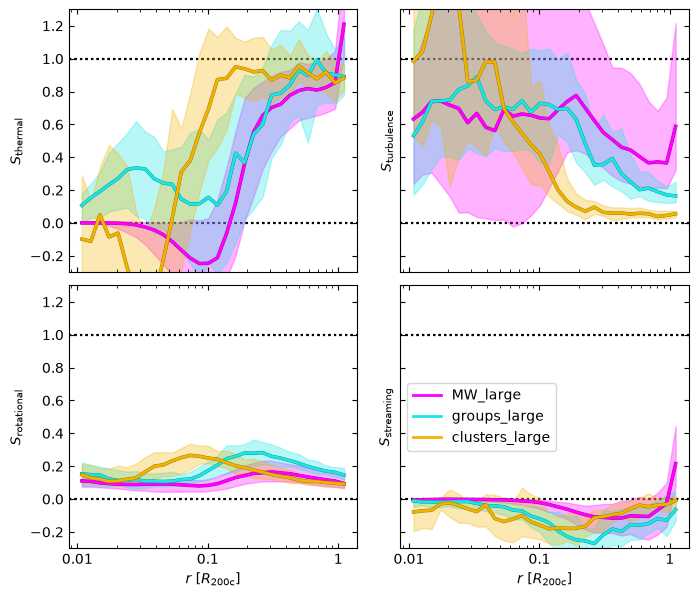

In [36]:
from scipy.ndimage import gaussian_filter1d

#===============
# Set up figure
#===============
inner_radius, outer_radius, number_radial_bins = 0.01, 1.2, np.shape(S_thermal)[1]

multiplicative_factor = (outer_radius / inner_radius)**(1.0 / number_radial_bins)
bin_edges   = inner_radius * multiplicative_factor**np.arange(number_radial_bins + 1)
bin_centers = np.sqrt(bin_edges[:-1] * bin_edges[1:])

fig = plt.figure(figsize=(8, 7))
gs = fig.add_gridspec(2, 2, height_ratios=[1,1],width_ratios=[1,1], hspace=0.05, wspace=0.15)

ax_left_top = fig.add_subplot(gs[0])
ax_right_top = fig.add_subplot(gs[1])
ax_left_bot = fig.add_subplot(gs[2], sharex=ax_left_top)
ax_right_bot = fig.add_subplot(gs[3], sharex=ax_right_top)

axes = [ax_left_top, ax_right_top, ax_left_bot, ax_right_bot]
labels = np.array([r'S_\mathrm{thermal}', r'S_\mathrm{turbulence}' ,r'S_\mathrm{rotational}', r'S_\mathrm{streaming}'])
colors = [(1.0, 0.0, 1.0), (0.1, 0.9, 0.9), (0.95, 0.7, 0.0),  (0.95, 0.7, 0.5)]
dark_factor = 0.6
dark = [tuple(dark_factor * x for x in (1.0, 0.0, 1.0)), tuple(dark_factor * x for x in (0.1, 0.9, 0.9)),
        tuple(dark_factor * x for x in (0.95, 0.7, 0.0)),tuple(dark_factor * x for x in (0.95, 0.7, 0.5))]

#===============
# Paramters
#===============
sim = "L0100N0752/Thermal"
snapnum = "0127"
box = "L100m7"

additional_naming = "swift"

for i, objects in enumerate(["MW_large", "groups_large", "clusters_large"]):
    #================
    # Load file data
    #================
    file = f'halo_properties_{snapnum}_{additional_naming}_{box}_{objects}.hdf5'
    data = sw.load(file)

    S_thermal = data.spherical_overdensity_200_crit.euler_mass_thermal_support
    S_turbulence = data.spherical_overdensity_200_crit.euler_mass_turbulent_support
    S_rotational = data.spherical_overdensity_200_crit.euler_mass_rotational_support
    S_streaming = data.spherical_overdensity_200_crit.euler_mass_streaming_support
    M_total = data.spherical_overdensity_200_crit.total_mass
    SO = data.spherical_overdensity_200_crit.soradius

    SPH_dat = (np.nanmedian(S_thermal, axis=0),
            np.nanmedian(S_turbulence, axis=0),
            np.nanmedian(S_rotational, axis=0),
            np.nanmedian(S_streaming, axis=0))

    SPH_dat_i = (S_thermal,
                S_turbulence,
                S_rotational,
                S_streaming)

    if particles:
        particle_dat = (S_thermal_particle,
                        np.full(20, np.nan),
                        S_rotational_particle,
                        S_streaming_particle)

    #===============================
    # Plot results for each EM-term
    #===============================
    for j, ax in enumerate(axes):
        # for term in SPH_dat_i[i]:
        #     ax.plot(bin_centers, term, lw=1, c='grey', ls="-", alpha=0.1)
        ax.plot(bin_centers, SPH_dat[j], lw=2.5, c=dark[i], ls="-")
        ax.plot(bin_centers, SPH_dat[j], lw=2, c=colors[i], ls="-", label=rf'{objects}')
        if particles:
            ax.plot(particle_bins, particle_dat[j], lw=2, c='black', ls="--", label=f'Particle Binning')
        ax.fill_between(bin_centers, np.percentile(SPH_dat_i[j], 25, axis=0), np.percentile(SPH_dat_i[j], 75, axis=0), color=colors[i], alpha=0.3)

        ax.set_ylim(-0.3, 1.3)
        ax.set_ylabel(f'${labels[j]}$')
        ax.set_xscale('log')
        ax.tick_params(axis='both', which='both', right=True, top=True, labelleft=True, labelbottom=True, direction="in")
        ax.axhline(y=1, c='black', ls=':', zorder=-1)
        ax.axhline(y=0, c='black', ls=':', zorder=-1)

#==========================
# Finish and export figure
#==========================

ax_left_bot.xaxis.set_ticks([0.01, 0.1, 1], ["0.01", "0.1", "1"])
ax_right_bot.xaxis.set_ticks([0.01, 0.1, 1], ["0.01", "0.1", "1"])
ax_right_bot.legend()
ax_left_bot.set_xlabel(r"$r\ [R_\mathrm{200c}]$")
ax_right_bot.set_xlabel(r"$r\ [R_\mathrm{200c}]$")

plt.setp(ax_left_top.get_xticklabels(), visible=False)
plt.setp(ax_right_top.get_xticklabels(), visible=False)
plt.setp(ax_right_top.get_yticklabels(), visible=False)
plt.setp(ax_right_bot.get_yticklabels(), visible=False)
plt.savefig(f'Euler_mass_terms_{additional_naming}_{box}.png', bbox_inches='tight', dpi=300)
plt.show()

### Total of all terms

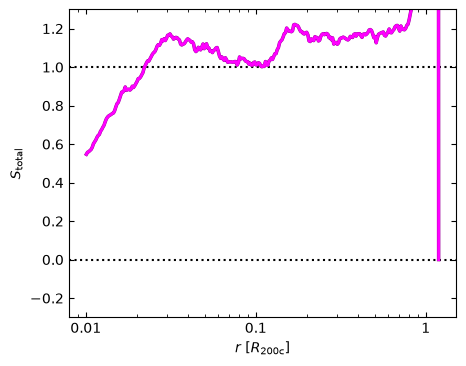

In [6]:
inner_radius, outer_radius, number_radial_bins = 0.01, 1.2, np.shape(S_thermal)[1]

multiplicative_factor = (outer_radius / inner_radius)**(1.0 / number_radial_bins)
bin_edges   = inner_radius * multiplicative_factor**np.arange(number_radial_bins + 1)
bin_centers = np.sqrt(bin_edges[:-1] * bin_edges[1:])

fig = plt.figure(figsize=(5, 4))


colors = [(1.0, 0.0, 1.0), (0.1, 0.9, 0.9), (0.95, 0.7, 0.0),  (0.95, 0.7, 0.5)]
dark_factor = 0.6
dark = [tuple(dark_factor * x for x in (1.0, 0.0, 1.0)), tuple(dark_factor * x for x in (0.1, 0.9, 0.9)),
        tuple(dark_factor * x for x in (0.95, 0.7, 0.0)),tuple(dark_factor * x for x in (0.95, 0.7, 0.5))]

SPH_dat = np.array([np.nanmedian(S_thermal, axis=0),
                    np.nanmedian(S_turbulence, axis=0),
                    np.nanmedian(S_rotational, axis=0),
                    np.nanmedian(S_streaming, axis=0)])

S_total = np.sum(SPH_dat, axis=0)

plt.plot(bin_centers, S_total, lw=2.5, c=dark[0], ls="-")
plt.plot(bin_centers, S_total, lw=2, c=colors[0], ls="-")

for r in bin_centers:
    ax.axvline(x=r, ls=':', c='grey')

plt.ylim(-0.3, 1.3)
plt.xlabel(r"$r\ [R_\mathrm{200c}]$")
plt.ylabel(r'$S_\mathrm{total}$')
plt.xscale('log')
plt.tick_params(axis='both', which='both', right=True, top=True, labelleft=True, labelbottom=True, direction="in")
plt.axhline(y=1, c='black', ls=':', zorder=-1)
plt.axhline(y=0, c='black', ls=':', zorder=-1)
plt.xticks([0.01, 0.1, 1], ["0.01", "0.1", "1"])

#plt.savefig(f'EM_testv1.pdf', bbox_inches='tight')
plt.show()

### Convergence of mass

In [41]:
sim = "L0025N0188/Thermal"
snapnum = "0127"

# file_BRP = f'halo_properties_{snapnum}_BRP.hdf5'
# data_BRP = sw.load(file_BRP)

# file_CSPM = f'halo_properties_{snapnum}_CSPM.hdf5'
# data_CSPM = sw.load(file_CSPM)

file_swift = f'halo_properties_{snapnum}_swift_L100m7_clusters_large.hdf5'
data_swift = sw.load(file_swift)

enclosed_gas_mass = data_swift.spherical_overdensity_200_crit.test_field2 * u.Msun
SO = data_swift.spherical_overdensity_200_crit.soradius

# density_BRP = data_BRP.spherical_overdensity_200_crit.test_field1 * u.Msun * u.Mpc ** (-3)
# pressure_gradient_BRP = data_BRP.spherical_overdensity_200_crit.test_field3 * u.kg * u.Mpc ** (-2) * u.s ** (-2)
# pressure_BRP = data_BRP.spherical_overdensity_200_crit.test_field4 * u.kg * u.Mpc ** (-1) * u.s ** (-2)

# density_CSPM = data_CSPM.spherical_overdensity_200_crit.test_field1 * u.Msun * u.Mpc ** (-3)
# pressure_gradient_CSPM = data_CSPM.spherical_overdensity_200_crit.test_field3 * u.kg * u.Mpc ** (-2) * u.s ** (-2)
# pressure_CSPM = data_CSPM.spherical_overdensity_200_crit.test_field4 * u.kg * u.Mpc ** (-1) * u.s ** (-2)

density_swift = data_swift.spherical_overdensity_200_crit.test_field1 * u.Msun * u.Mpc ** (-3)
pressure_gradient_swift = data_swift.spherical_overdensity_200_crit.test_field3 * u.kg * u.Mpc ** (-2) * u.s ** (-2)
pressure_swift = data_swift.spherical_overdensity_200_crit.test_field4 * u.kg * u.Mpc ** (-1) * u.s ** (-2)

# num_particles = sw.load('halo_properties_0127.hdf5').spherical_overdensity_200_crit.test_field4


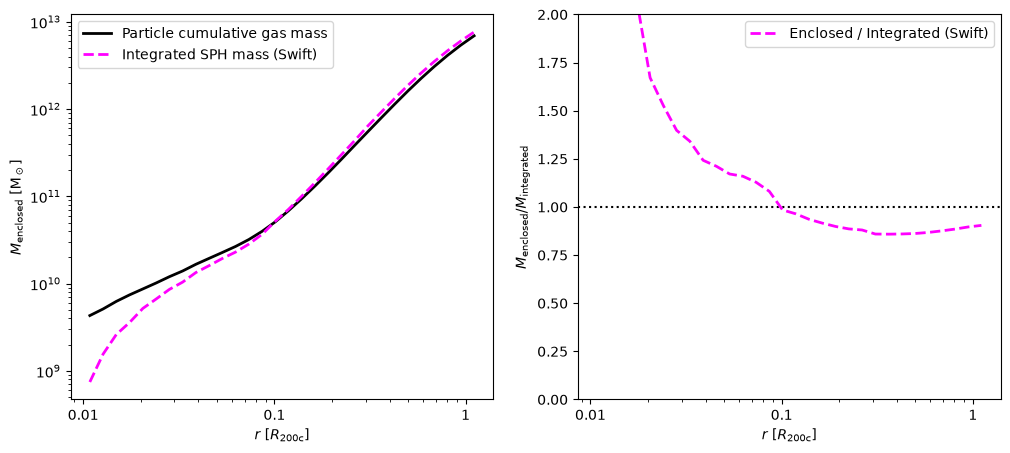

In [49]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

radii = bin_centers[None, :] * SO[:, None]
dr = np.diff(bin_edges)[None, :] * SO[:, None]

labels = ['Swift']
# labels = ['BRP', 'CSPM', 'Swift']
linestyles = ['--', '-.', ':']

ax1.plot(bin_centers, np.mean(enclosed_gas_mass, axis=0).to(u.Msun), lw=2, c='black', ls="-", label='Particle cumulative gas mass')

# for i, density in enumerate([density_BRP, density_CSPM, density_swift]):
for i, density in enumerate([density_swift]):
    integrated_mass_each_radius = 4 * np.pi * density * (radii ** 2) * dr
    cumulative_mass = np.cumsum(integrated_mass_each_radius, axis=1)

    ax1.plot(bin_centers, np.mean(cumulative_mass, axis=0).to(u.Msun), lw=2, c=colors[i], ls=linestyles[i], label=f'Integrated SPH mass ({labels[i]})')
    ax2.plot(bin_centers, np.mean(enclosed_gas_mass, axis=0) / np.mean(cumulative_mass, axis=0), lw=2, c=colors[i], ls=linestyles[i], label=f'Enclosed / Integrated ({labels[i]})')

    ax1.set_ylabel(r'$M_\mathrm{enclosed}\ [\mathrm{M}_\odot]$')
    ax1.set_xlabel(r"$r\ [R_\mathrm{200c}]$")
    ax1.set_yscale('log'), ax1.set_xscale('log')
    ax1.xaxis.set_ticks([0.01, 0.1, 1], ["0.01", "0.1", "1"])
    ax1.legend()

    ax2.axhline(y=1, c='black', ls=':', zorder=-1)
    ax2.set_ylabel(r'$M_\mathrm{enclosed} / M_\mathrm{integrated}$')
    ax2.set_xlabel(r"$r\ [R_\mathrm{200c}]$")
    ax2.set_ylim(0, 2)
    ax2.set_xscale('log')
    ax2.xaxis.set_ticks([0.01, 0.1, 1], ["0.01", "0.1", "1"])
    ax2.legend()

# for ax in [ax1, ax2]:
#     ax_top = ax.twiny()

#     indices = [0, 5, 10, 20, 29]
#     ax_top.set_xscale('log')
#     ax_top.set_xlim(ax.get_xlim())
#     ax_top.set_xticks(bin_centers[indices], )
#     ax_top.set_xticklabels(np.median(num_particles, axis=0).value[indices])
#     ax_top.set_xlabel('Median number of enclosed gas particles')

plt.savefig(f'Mass_profile_comparison.png', bbox_inches='tight', dpi=300)
plt.show()

### Pressure gradient profiles

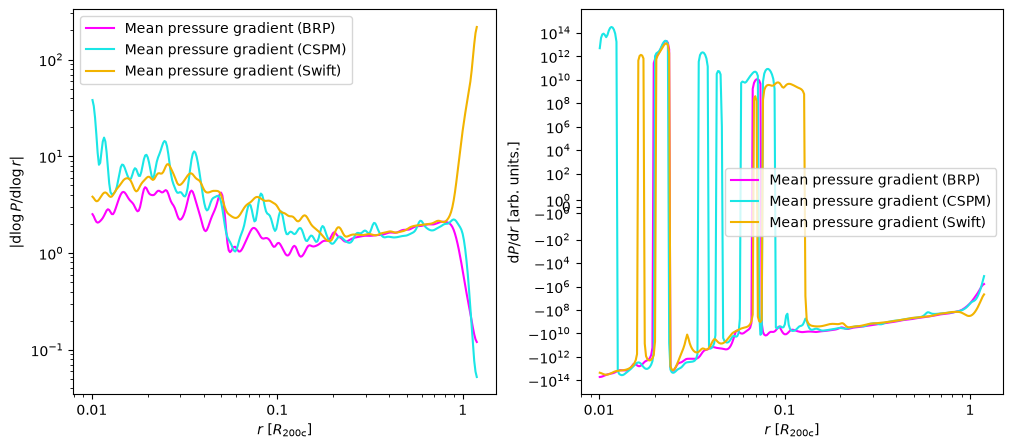

In [30]:
from scipy.ndimage import gaussian_filter

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

radii = bin_centers[None, :] * SO[:, None]

# labels = ['BRP', 'Swift', 'Combi']
labels = ['BRP', 'CSPM', 'Swift']
linestyles = ['--', '-.', ':']

# ax1.axhline(y=0, c='black', ls=':', zorder=-1)

for i, (pressures, pressure_gradient) in enumerate(zip([pressure_BRP, pressure_CSPM, pressure_swift], 
                                                     [pressure_gradient_BRP, pressure_gradient_CSPM, pressure_gradient_swift])):

# for i, (pressures, pressure_gradient) in enumerate(zip([pressure_BRP, pressure_swift, pressure_combi], 
#                                                      [pressure_gradient_BRP, pressure_gradient_swift, pressure_gradient_combi])):

    log_dP_dr_mean = np.nanmean(np.abs(pressure_gradient * radii / pressures), axis=0)
    # log_dP_dr_median = np.nanmedian(pressure_gradient * radii / pressures, axis=0)
    # dP_dr = np.nanmean(pressure_gradient, axis=0)

    ax1.plot(bin_centers, gaussian_filter(log_dP_dr_mean, sigma=2), c=colors[i], ls="-", label=f'Mean pressure gradient ({labels[i]})')
    # ax1.plot(bin_centers, gaussian_filter(log_dP_dr_median, sigma=2), lw=2, c=colors[i], ls=":", label=f'Median pressure gradient ({labels[i]})')

    ax1.set_ylabel(r'$|\mathrm{d}\log P/\mathrm{d}\log r|$')
    ax1.set_xlabel(r"$r\ [R_\mathrm{200c}]$")
    ax1.set_xscale('log'), ax1.set_yscale('log')
    ax1.xaxis.set_ticks([0.01, 0.1, 1], ["0.01", "0.1", "1"])
    ax1.legend()

    dP_dr_mean = np.nanmean(pressure_gradient, axis=0)
    # log_dP_dr_median = np.nanmedian(pressure_gradient * radii / pressures, axis=0)
    # dP_dr = np.nanmean(pressure_gradient, axis=0)

    ax2.plot(bin_centers, gaussian_filter(dP_dr_mean, sigma=2), 
             c=colors[i], ls="-", label=f'Mean pressure gradient ({labels[i]})')
    # ax1.plot(bin_centers, gaussian_filter(log_dP_dr_median, sigma=2), lw=2, c=colors[i], ls=":", label=f'Median pressure gradient ({labels[i]})')

    ax2.set_ylabel(r'$\mathrm{d} P/\mathrm{d}r$ [arb. units.]')
    ax2.set_xlabel(r"$r\ [R_\mathrm{200c}]$")
    ax2.set_xscale('log'), ax2.set_yscale('symlog')
    ax2.xaxis.set_ticks([0.01, 0.1, 1], ["0.01", "0.1", "1"])
    ax2.legend()

plt.savefig(f'Pressure_gradient_profile_comparison.png', bbox_inches='tight', dpi=300)
plt.show()

### Density profiles

In [39]:
sim = "L0025N0188/Thermal"
snapnum = "0127"

file_BRP = f'halo_properties_{snapnum}_BRP.hdf5'
data_BRP = sw.load(file_BRP)

file_CSPM = f'halo_properties_{snapnum}_CSPM.hdf5'
data_CSPM = sw.load(file_CSPM)

file_swift = f'halo_properties_{snapnum}_swift.hdf5'
data_swift = sw.load(file_swift)

enclosed_gas_mass = data_BRP.spherical_overdensity_200_crit.test_field2 * u.Msun
SO = data_BRP.spherical_overdensity_200_crit.soradius

density_BRP = data_BRP.spherical_overdensity_200_crit.test_field1 * u.Msun * u.Mpc ** (-3)
pressure_gradient_BRP = data_BRP.spherical_overdensity_200_crit.test_field3 * u.kg * u.Mpc ** (-2) * u.s ** (-2)
pressure_BRP = data_BRP.spherical_overdensity_200_crit.test_field4 * u.kg * u.Mpc ** (-1) * u.s ** (-2)

density_CSPM = data_CSPM.spherical_overdensity_200_crit.test_field1 * u.Msun * u.Mpc ** (-3)
pressure_gradient_CSPM = data_CSPM.spherical_overdensity_200_crit.test_field3 * u.kg * u.Mpc ** (-2) * u.s ** (-2)
pressure_CSPM = data_CSPM.spherical_overdensity_200_crit.test_field4 * u.kg * u.Mpc ** (-1) * u.s ** (-2)

density_swift = data_swift.spherical_overdensity_200_crit.test_field1 * u.Msun * u.Mpc ** (-3)
pressure_gradient_swift = data_swift.spherical_overdensity_200_crit.test_field3 * u.kg * u.Mpc ** (-2) * u.s ** (-2)
pressure_swift = data_swift.spherical_overdensity_200_crit.test_field4 * u.kg * u.Mpc ** (-1) * u.s ** (-2)

num_particles = sw.load('halo_properties_0127.hdf5').spherical_overdensity_200_crit.test_field4

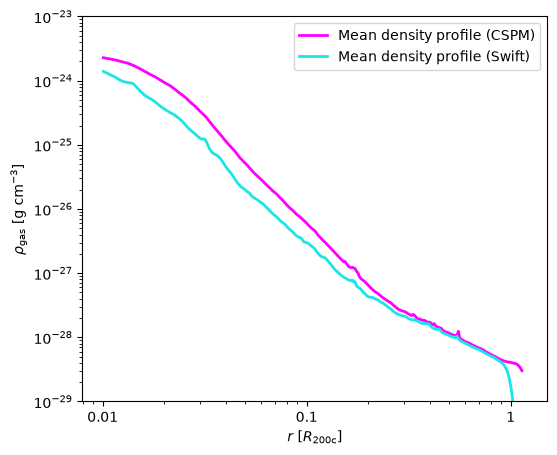

In [38]:
fig, (ax1) = plt.subplots(1, 1, figsize=(6, 5))

radii = bin_centers[None, :] * SO[:, None]

labels = ['CSPM', 'Swift']
# labels = ['BRP', 'CSPM', 'Swift']
linestyles = ['--', '-.', ':']

# ax1.plot(bin_centers, np.mean(enclosed_gas_mass, axis=0).to(u.Msun), lw=2, c='black', ls="-", label='Particle cumulative gas mass')

# for i, density in enumerate([density_BRP, density_CSPM, density_swift]):
for i, density in enumerate([density_CSPM, density_swift]):

    ax1.plot(bin_centers, np.mean(density, axis=0).to(u.g * u.cm**(-3)), lw=2, c=colors[i], ls="-", label=f'Mean density profile ({labels[i]})')
    # ax1.plot(bin_centers, np.median(density, axis=0).to(u.g * u.cm**(-3)), lw=2, c=colors[i], ls="--", label=f'Median density profile ({labels[i]})')

    ax1.set_ylabel(r'$\rho_\mathrm{gas}\ [\mathrm{g}\ \mathrm{cm}^{-3}]$')
    ax1.set_xlabel(r"$r\ [R_\mathrm{200c}]$")
    ax1.set_yscale('log'), ax1.set_xscale('log')
    ax1.xaxis.set_ticks([0.01, 0.1, 1], ["0.01", "0.1", "1"])
    ax1.set_ylim(1e-29, 1e-23)
    ax1.legend()

plt.savefig(f'Density_profile_comparison.png', bbox_inches='tight', dpi=300)
plt.show()

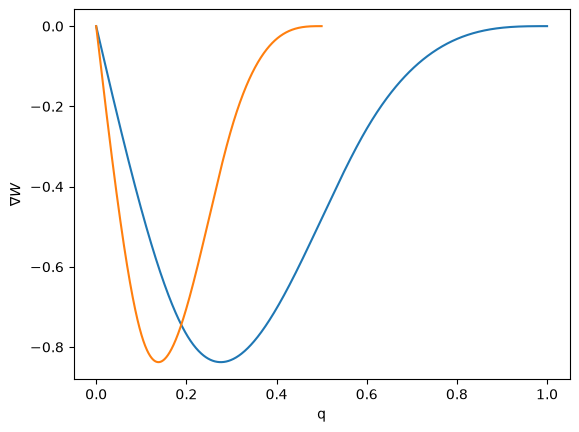

In [37]:
qs = np.linspace(0, 1, 1000)
kernel_derivative = np.zeros(1000)

def kernel_gradient(q):
    return - 4 * (max(0.0, 1 - q))**3 + 20 * (max(0.0, 3/5 - q))**3 - 40 * (max(0.0, 1/5 - q))**3

for i, q in enumerate(qs):
    kernel_derivative[i] = kernel_gradient(q)

plt.plot(qs, kernel_derivative)
plt.plot(0.5*qs, kernel_derivative)
plt.xlabel("q"), plt.ylabel(r"$\nabla W$")
plt.show()